# 04 · Symptom model — the metadata baseline

**Project:** Skin Lesion Triage · BIU DS23 Capstone
**Owner:** Data / Model · **Charter:** baseline table row 2, and M2

This notebook asks whether the questionnaire baseline can be improved on. The **baseline** is fixed in
notebook 02, Cell 8b: a logistic regression on variant D, patient AUC 0.867, specified before any model was
fitted and never tuned on validation. That is the number the image model is measured against.

Here two models are compared under a rule set in advance, the winner is interpreted and calibrated, and its
scores are written for a fusion layer. The winner reaches a higher AUC — but it was **selected on the same
validation patients it reports on**, so it is a study of how far the form can go, not a replacement bar.

## The data it uses

`data/processed/pad_symptom_features.csv` — one row per lesion (`patient_id::lesion_id`), eight fields:
age, body site, and the six symptom questions. The split is the frozen patient-level one from notebook 02.

## Three rules this notebook obeys

**Test patients are never loaded.** The first data cell drops them and asserts they are gone. Model selection,
threshold choice and calibration happen on train and validation only.

**Every lesion is scored; no missingness indicator ever reaches a model.** `grew` and `changed` are
unanswered for ~20% of lesions, 87–88% of them malignant (notebook 02, Cell 6b). Dropping them (complete-case)
removes ~40% of the cancers and evaluates on an easier population; keeping "unanswered" as a feature leaks the
label. So missing answers are imputed with the most frequent answer **inside** the pipeline, fitted per fold,
with no indicator — variant D in notebook 02. This also means the fusion layer receives a symptom score for
every lesion and cannot learn "no score = cancer". In the app all six answers are mandatory, so imputation
only matters for training and evaluating on PAD. Complete-case results are reported as a subgroup.

**The operating point is the charter's.** Sensitivity, PPV and flag rate at 5 / 10 / 15 urgent slots for
100 arrivals, at 5 / 10 / 20% prevalence — the same function as notebook 02, Cell 8b.

| Split | Lesions | Complete | Incomplete (≈87% malignant) |
|---|---|---|---|
| train | 1,199 | 958 | 241 |
| val | 290 | 227 | 63 |

### Outputs

- `models/symptom_model.joblib` — selected, calibrated model.
- `data/processed/symptom_scores_train_oof.csv` — calibrated out-of-fold predictions for training lesions.
- `data/processed/symptom_scores_fusion.csv` — train (OOF) and validation scores for every development lesion.
- `reports/symptom_model_results.csv` — lesion-level model comparison.
- `reports/symptom_patient_results.csv` — patient-level evaluation.
- `reports/symptom_capacity_results.csv` — sensitivity, PPV and flag rate at the charter's operating points.


In [1]:
# Cell 1 · Configuration (identical in every notebook)
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    PROJECT = "/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers"
else:
    PROJECT = os.path.abspath("..")

RAW       = os.path.join(PROJECT, "data", "raw")
PROCESSED = os.path.join(PROJECT, "data", "processed")
FIGURES   = os.path.join(PROJECT, "reports", "figures")
MODELS    = os.path.join(PROJECT, "models")
for d in (RAW, PROCESSED, FIGURES, MODELS):
    os.makedirs(d, exist_ok=True)

SEED = 42

print("project  :", PROJECT)
print("models   :", MODELS)


Mounted at /content/drive
project  : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers
models   : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/models


In [2]:
# Cell 2 · Load the features and remove the test split before anything else
import pandas as pd, numpy as np

FEATURES_NUM = ["age"]
FEATURES_CAT = ["region", "itch", "grew", "hurt", "changed", "bleed", "elevation"]
FEATURES     = FEATURES_NUM + FEATURES_CAT
SYMPTOMS     = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]

feat = pd.read_csv(os.path.join(PROCESSED, "pad_symptom_features.csv"))
print(f"rows in file: {len(feat):,}")

# Test patients leave the notebook here and do not come back.
dev = feat[feat["split"].isin(["train", "val"])].copy()
assert "test" not in set(dev["split"]), "test rows survived the filter"
print(f"development lesions: {len(dev):,}  (test removed: {len(feat) - len(dev):,})")


# Normalize symptom answers to 1 / 0 / NaN
BOOL = {
    True: 1, False: 0,
    1: 1, 0: 0,
    "True": 1, "False": 0,
    "TRUE": 1, "FALSE": 0,
    "1": 1, "0": 0
}

for c in SYMPTOMS:
    original = dev[c].copy()
    dev[c] = original.map(BOOL)

    unexpected = original[
        original.notna() & dev[c].isna()
    ].unique()

    assert len(unexpected) == 0, (
        f"Unexpected values in {c}: {unexpected}"
    )

print("Symptom columns normalized successfully.")

print("\nMissing values by feature:")
print(dev[FEATURES].isna().sum())

dev.head()


rows in file: 1,891
development lesions: 1,489  (test removed: 402)
Symptom columns normalized successfully.

Missing values by feature:
age            0
region         0
itch           5
grew         302
hurt           5
changed      298
bleed          5
elevation      2
dtype: int64


,lesion_key,patient_id,split,label,age,region,itch,grew,hurt,changed,bleed,elevation
1,PAT_1006::53,PAT_1006,train,0,63,FOREARM,0.0,0.0,0.0,0.0,0.0,0.0
2,PAT_1008::59,PAT_1008,train,0,64,FACE,0.0,1.0,0.0,0.0,0.0,1.0
3,PAT_100::393,PAT_100,val,0,14,FACE,0.0,0.0,0.0,0.0,0.0,0.0
5,PAT_1014::85,PAT_1014,val,0,41,FOREARM,1.0,0.0,0.0,0.0,0.0,0.0
6,PAT_1014::86,PAT_1014,val,0,41,FOREARM,1.0,0.0,0.0,0.0,0.0,0.0


## 1 · The training and validation sets

The source file contains train, validation and test records. Test records are excluded immediately after
loading and are not used for model development or evaluation.

All development lesions are kept. A `complete` flag records which lesions had every answer, for subgroup
reporting only — it is never a model input.

In [3]:
# Cell 3 · Build the matrices — ALL development lesions (variant D policy, notebook 02)
# Missing answers stay NaN here and are imputed inside each model's pipeline, fitted per fold.
# `complete` is kept for subgroup reporting only; it never reaches a model.

dev["complete"] = dev[FEATURES].notna().all(axis=1)

train = dev[dev.split == "train"].copy()
val   = dev[dev.split == "val"].copy()

X_train, y_train, g_train = train[FEATURES], train["label"], train["patient_id"].astype(str)
X_val,   y_val            = val[FEATURES],   val["label"]

assert len(train) == 1199 and len(val) == 290, "development lesion counts differ from notebook 03"
overlap = set(train["patient_id"]) & set(val["patient_id"])
assert not overlap, f"patient overlap between train and val: {len(overlap)}"

print(f"train : {len(train):,} lesions, {int(y_train.sum()):,} malignant "
      f"({100*y_train.mean():.1f}%), {g_train.nunique():,} patients")
print(f"val   : {len(val):,} lesions, {int(y_val.sum()):,} malignant ({100*y_val.mean():.1f}%)")
print("patient overlap train/val: 0 (asserted)")

print("\n--- completeness (reporting only) ---")
for name, subset in [("train", train), ("val", val)]:
    for flag, part in subset.groupby("complete"):
        print(f"{name:<5} {'complete  ' if flag else 'incomplete'}: {len(part):>5,} lesions, "
              f"{100 * part['label'].mean():5.1f}% malignant")

train : 1,199 lesions, 528 malignant (44.0%), 878 patients
val   : 290 lesions, 127 malignant (43.8%)
patient overlap train/val: 0 (asserted)

--- completeness (reporting only) ---
train incomplete:   241 lesions,  88.8% malignant
train complete  :   958 lesions,  32.8% malignant
val   incomplete:    63 lesions,  82.5% malignant
val   complete  :   227 lesions,  33.0% malignant


## 2 · Two models, one protocol

Both are selected by cross-validation **inside the training split**, grouped by patient, and then compared
once on validation. Nothing is chosen by looking at validation twice.

| | |
|---|---|
| **Logistic regression** | the baseline the charter names. Linear, inspectable, and its coefficients are a clinical statement that can be checked against medical sense |
| **Gradient boosting** | the "improved" variant: it can use interactions between symptoms, at the cost of interpretability |


In [4]:
# Cell 4 · Model A - logistic regression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

pre = make_column_transformer(
    (StandardScaler(), FEATURES_NUM),                                 # age: never missing
    (make_pipeline(SimpleImputer(strategy="most_frequent"),           # fitted per fold, no indicator
                   OneHotEncoder(handle_unknown="ignore", min_frequency=10)), FEATURES_CAT))

logreg = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=SEED))

cv_auc = cross_val_score(logreg, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
print(f"logistic regression · CV on train : AUC {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")

logreg.fit(X_train, y_train)
p_val_lr = logreg.predict_proba(X_val)[:, 1]
print(f"logistic regression · validation  : AUC {roc_auc_score(y_val, p_val_lr):.3f} "
      f"| AP {average_precision_score(y_val, p_val_lr):.3f}")


logistic regression · CV on train : AUC 0.859 +/- 0.016
logistic regression · validation  : AUC 0.852 | AP 0.840


In [5]:
# Cell 5 · Model B - gradient boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Impute BEFORE the trees: HistGradientBoosting routes NaN to its own branch, which is a
# built-in missingness indicator - exactly the leak notebook 02 rules out. Imputation is
# fitted inside the pipeline, so in cross-validation it is learned from each training fold only.
pre_tree = ColumnTransformer([
    ("num", "passthrough", FEATURES_NUM),                                     # age: never missing
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
     FEATURES_CAT)])

gb = make_pipeline(pre_tree, HistGradientBoostingClassifier(
    max_depth=3, max_iter=200, learning_rate=0.06,
    categorical_features=list(range(len(FEATURES_NUM), len(FEATURES))),
    class_weight="balanced", random_state=SEED))

cv_auc_gb = cross_val_score(gb, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc")
print(f"gradient boosting · CV on train : AUC {cv_auc_gb.mean():.3f} +/- {cv_auc_gb.std():.3f}")

gb.fit(X_train, y_train)
p_val_gb = gb.predict_proba(X_val)[:, 1]
print(f"gradient boosting · validation  : AUC {roc_auc_score(y_val, p_val_gb):.3f} "
      f"| AP {average_precision_score(y_val, p_val_gb):.3f}")

print("\nWith eight fields and ~1,200 training rows, a large gap between the two would be surprising.")
print("If gradient boosting does not clearly win, the linear model is the better choice: it is the")
print("charter's baseline, and its coefficients can be read by a clinician.")

gradient boosting · CV on train : AUC 0.862 +/- 0.019
gradient boosting · validation  : AUC 0.873 | AP 0.840

With eight fields and ~1,200 training rows, a large gap between the two would be surprising.
If gradient boosting does not clearly win, the linear model is the better choice: it is the
charter's baseline, and its coefficients can be read by a clinician.



## 3 · What the model learned

Logistic Regression coefficients help us understand which features influence the model's predictions and in which direction.

For binary symptoms, odds ratios compare Yes (1) with No (0), holding other features constant.

Bleeding, elevation, and lesion change showed the strongest positive associations with predicted malignancy.

These associations reflect patterns learned from PAD-UFES-20, not proven clinical relationships. Unexpected coefficients should be investigated as potential data or modeling issues, rather than automatically treated as bugs.

Body-site coefficients are encoding-dependent and should not be interpreted as direct clinical risk comparisons between anatomical locations.

**Caveat — `grew` and `changed`.** These two answers are missing for ~20% of lesions, 87–88% of them malignant, and the pipeline imputes the most frequent answer, "no". That fills the "no" group with cancers and pulls both coefficients down: `grew` even comes out below 1 (OR 0.89), although in the raw development data 53.7% of "grew = yes" lesions are malignant against 15.8% of "no" (notebook 02, Cell 6). These two coefficients are an imputation artefact, not a clinical finding. The price is paid in interpretation only; no missingness signal reaches the model.


Model coefficient interpretation:
                  feature              comparison   coef  odds_ratio
                    bleed               Yes vs No  1.851       6.365
                elevation               Yes vs No  1.792       6.004
              region_NOSE Encoded category effect  1.616       5.035
                  changed               Yes vs No  1.337       3.808
           region_ABDOMEN Encoded category effect -1.126       0.324
             region_SCALP Encoded category effect -0.995       0.370
           region_FOREARM Encoded category effect -0.935       0.393
                     hurt               Yes vs No  0.927       2.527
              region_NECK Encoded category effect  0.788       2.199
             region_CHEST Encoded category effect  0.422       1.525
               region_EAR Encoded category effect  0.418       1.519
              region_BACK Encoded category effect  0.412       1.510
               region_ARM Encoded category effect -0.330       0.719


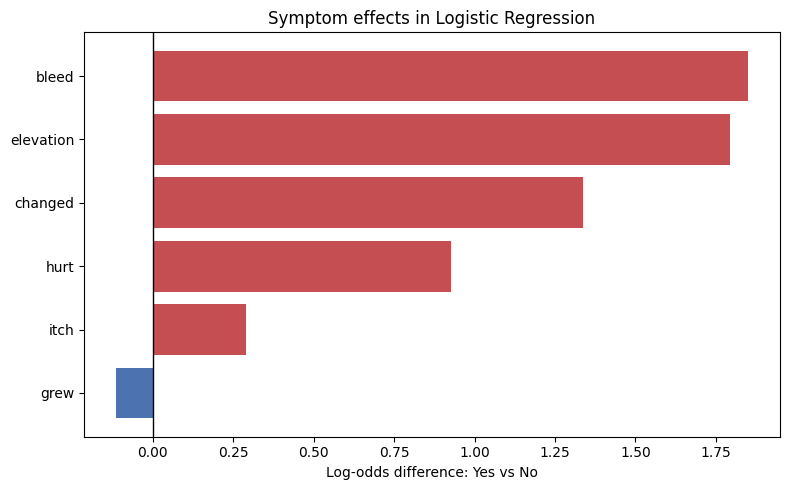

In [6]:
# Cell 6 · Interpreting Logistic Regression coefficients
import matplotlib.pyplot as plt

# Extract feature names and trained coefficients
names = logreg[:-1].get_feature_names_out()
coefs = logreg[-1].coef_[0]

coef_dict = {
    name.split("__")[-1]: coef
    for name, coef in zip(names, coefs)
}

rows = []

# Binary symptoms: compare YES (1) directly with NO (0)
for symptom in SYMPTOMS:
    yes_key = f"{symptom}_1.0"
    no_key = f"{symptom}_0.0"

    if yes_key in coef_dict and no_key in coef_dict:
        effect = coef_dict[yes_key] - coef_dict[no_key]

        rows.append({
            "feature": symptom,
            "comparison": "Yes vs No",
            "coef": effect,
            "odds_ratio": np.exp(effect)
        })

# Age: StandardScaler makes the coefficient "per 1 SD of age", which is not readable.
# Convert it to the effect of being 10 years older, using the scaler's own std.
if "age" in coef_dict:
    age_sd = logreg[0].named_transformers_["standardscaler"].scale_[0]
    per_10y = coef_dict["age"] / age_sd * 10

    rows.append({
        "feature": "age (per 10 years)",
        "comparison": "Continuous",
        "coef": per_10y,
        "odds_ratio": np.exp(per_10y)
    })

# Body site: coefficients relative to the model's
# encoded baseline (not pairwise comparisons)
for name, coef in coef_dict.items():
    if name.startswith("region_"):
        rows.append({
            "feature": name,
            "comparison": "Encoded category effect",
            "coef": coef,
            "odds_ratio": np.exp(coef)
        })

effects = pd.DataFrame(rows)
effects = effects.sort_values(
    "coef", key=abs, ascending=False
)

print("Model coefficient interpretation:")
print(
    effects.to_string(
        index=False,
        float_format=lambda v: f"{v:.3f}"
    )
)

# Plot symptom effects only
symptom_effects = effects[
    effects["feature"].isin(SYMPTOMS)
].sort_values("coef")

plt.figure(figsize=(8, 5))

colors = [
    "#C44E52" if x > 0 else "#4C72B0"
    for x in symptom_effects["coef"]
]

plt.barh(
    symptom_effects["feature"],
    symptom_effects["coef"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Log-odds difference: Yes vs No")
plt.title("Symptom effects in Logistic Regression")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES, "04_symptom_coefficients.png"),
    dpi=120
)

plt.show()


In [7]:
# Cell 6b · The full coefficient table
print(effects.to_string(index=False, float_format=lambda v: f"{v:7.3f}"))

                  feature              comparison    coef  odds_ratio
                    bleed               Yes vs No   1.851       6.365
                elevation               Yes vs No   1.792       6.004
              region_NOSE Encoded category effect   1.616       5.035
                  changed               Yes vs No   1.337       3.808
           region_ABDOMEN Encoded category effect  -1.126       0.324
             region_SCALP Encoded category effect  -0.995       0.370
           region_FOREARM Encoded category effect  -0.935       0.393
                     hurt               Yes vs No   0.927       2.527
              region_NECK Encoded category effect   0.788       2.199
             region_CHEST Encoded category effect   0.422       1.525
               region_EAR Encoded category effect   0.418       1.519
              region_BACK Encoded category effect   0.412       1.510
               region_ARM Encoded category effect  -0.330       0.719
                    

## 4 · Choosing between the two

Both models are trained. The choice is made once, on validation, with a margin: a difference in the fourth
decimal on 290 lesions is noise, and when the two are tied the linear model wins by default — it is the
charter's baseline and its coefficients are readable.


In [8]:
# Cell 7 · Model selection
auc_lr = roc_auc_score(y_val, p_val_lr)
auc_gb = roc_auc_score(y_val, p_val_gb)

# Prefer the simpler, inspectable model unless the other wins by a margin that 290 lesions
# can actually support. A difference in the fourth decimal is noise, not evidence.
MARGIN = 0.01
best_name, p_val = (("gradient boosting", p_val_gb) if auc_gb > auc_lr + MARGIN
                    else ("logistic regression", p_val_lr))

print(f"logistic regression {auc_lr:.4f} | gradient boosting {auc_gb:.4f} "
      f"| margin required {MARGIN}")
print(f"carried forward: {best_name}\n")


logistic regression 0.8523 | gradient boosting 0.8733 | margin required 0.01
carried forward: gradient boosting



## 5 · Where the model is weaker

A single average hides the subgroup that matters. The charter commits to reporting by age and skin tone, so
the breakdown is produced here rather than at the end.

Skin tone is joined from the raw metadata for reporting only — it is never a model input, because it is
recorded for just 65% of images and its absence tracks the diagnosis.


In [9]:
# Cell 8 · Subgroups on validation
val_eval = val.copy()
val_eval["score"] = p_val

raw = pd.read_csv(os.path.join(RAW, "pad_metadata_raw.csv")).replace({"UNK": np.nan, "": np.nan})
raw["lesion_key"] = raw["patient_id"].astype(str) + "::" + raw["lesion_id"].astype(str)
val_eval = val_eval.merge(raw[["lesion_key", "fitspatrick"]].drop_duplicates("lesion_key"),
                          on="lesion_key", how="left")

val_eval["age_band"] = pd.cut(val_eval["age"], [0, 40, 60, 75, 120],
                              labels=["<40", "40-59", "60-74", "75+"])

def report(df, by):
    out = []
    for name, g in df.groupby(by, observed=True):
        n, pos = len(g), int(g["label"].sum())
        auc = roc_auc_score(g["label"], g["score"]) if 0 < pos < n else np.nan
        out.append({str(by): name, "lesions": n, "malignant": pos,
                    "AUC": round(auc, 3) if auc == auc else "n/a"})
    return pd.DataFrame(out)

print("by age band:")
print(report(val_eval, "age_band").to_string(index=False))
print("\nby Fitzpatrick type (reporting only, never a feature):")
print(report(val_eval.dropna(subset=["fitspatrick"]), "fitspatrick").to_string(index=False))
print("\nAn AUC on a handful of lesions is noise. Read the counts first, the AUC second.")
print("\nby questionnaire completeness (reporting only, never a feature):")
print(report(val_eval, "complete").to_string(index=False))
print("Incomplete lesions are mostly malignant; their AUC is shown for transparency, not as a target.")


by age band:
age_band  lesions  malignant   AUC
     <40       40          4 0.931
   40-59       99         46 0.851
   60-74      103         51 0.872
     75+       48         26 0.830

by Fitzpatrick type (reporting only, never a feature):
 fitspatrick  lesions  malignant    AUC
         1.0       16         14    1.0
         2.0      111         81  0.839
         3.0       49         27  0.793
         4.0       10          4  0.958
         5.0        1          1    n/a

An AUC on a handful of lesions is noise. Read the counts first, the AUC second.

by questionnaire completeness (reporting only, never a feature):
 complete  lesions  malignant   AUC
    False       63         52 0.886
     True      227         75 0.876
Incomplete lesions are mostly malignant; their AUC is shown for transparency, not as a target.


## 6 · Calibration

The fusion layer adds this score to the image score, so the two have to live on the same scale. An
uncalibrated model can rank well and still output numbers that cannot be combined.

Calibration is fitted inside the training split only.


--- Calibration evaluation on validation ---
before: AUC 0.873 | Brier 0.1434
after : AUC 0.877 | Brier 0.1425
Calibration improved probability quality if Brier decreased. AUC may change slightly because calibration can affect ranking.


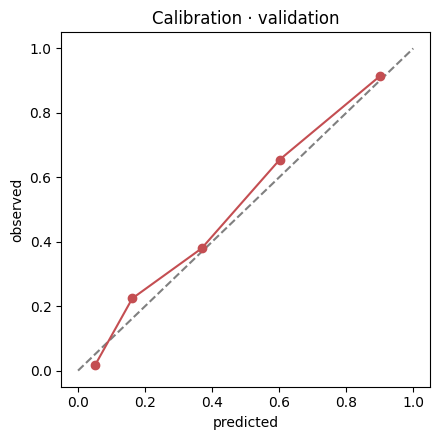


saved model -> /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/models/symptom_model.joblib
No scores are written here: this model saw every training lesion, so its training-set
predictions are in-sample. Cell 11 writes the fusion file from out-of-fold scores instead.


In [10]:
# Cell 9 · Calibrate and save the model
# The score files are written later: cell 11 builds them from out-of-fold predictions,
# which is the only version safe for the fusion layer.

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
import joblib

base = logreg if best_name == "logistic regression" else gb

# CalibratedClassifierCV does not forward `groups` to the splitter, so the folds are
# computed here and passed as a ready list. Grouping by patient is preserved this way.
cv_splits = list(cv.split(X_train, y_train, groups=g_train))

# Platt scaling rather than isotonic: with ~1,200 training rows, isotonic has enough freedom
# to fit the noise inside each fold.
calibrated = CalibratedClassifierCV(base, method="sigmoid", cv=cv_splits)
calibrated.fit(X_train, y_train)

p_before = p_val
p_after  = calibrated.predict_proba(X_val)[:, 1]
p_cal    = p_after                       # kept for the cells below

print("--- Calibration evaluation on validation ---")
print(f"before: AUC {roc_auc_score(y_val, p_before):.3f} | "
      f"Brier {brier_score_loss(y_val, p_before):.4f}")
print(f"after : AUC {roc_auc_score(y_val, p_after):.3f} | "
      f"Brier {brier_score_loss(y_val, p_after):.4f}")

print(
    "Calibration improved probability quality if Brier decreased. "
    "AUC may change slightly because calibration can affect ranking."
)


frac, mean_pred = calibration_curve(y_val, p_cal, n_bins=5, strategy="quantile")
plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.plot(mean_pred, frac, "o-", color="#C44E52")
plt.xlabel("predicted"); plt.ylabel("observed"); plt.title("Calibration · validation")
plt.tight_layout(); plt.savefig(os.path.join(FIGURES, "04_symptom_calibration.png"), dpi=120); plt.show()

joblib.dump({"model": calibrated,
             "features": FEATURES,
             "trained_on": "PAD train split, all lesions; missing answers imputed (most frequent), no indicator",
             "calibration": "sigmoid, 5 patient-grouped folds",
             "seed": SEED}, os.path.join(MODELS, "symptom_model.joblib"))

print(f"\nsaved model -> {os.path.join(MODELS, 'symptom_model.joblib')}")
print("No scores are written here: this model saw every training lesion, so its training-set")
print("predictions are in-sample. Cell 11 writes the fusion file from out-of-fold scores instead.")


In [11]:
# Cell 9A · Calibrated out-of-fold predictions from the SELECTED model
# Each training lesion is scored by a model that never saw it, so the fusion layer can be trained on
# these scores without leakage. The model is `base` - the one chosen in Cell 7 and calibrated in Cell 9 -
# so train (OOF) and validation scores in the fusion file come from the same model.

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.calibration import CalibratedClassifierCV
import numpy as np
import pandas as pd
import os

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_scores = np.full(len(train), np.nan)

for fold, (fit_idx, hold_idx) in enumerate(outer_cv.split(X_train, y_train, groups=g_train), start=1):
    X_fit      = X_train.iloc[fit_idx]
    y_fit      = y_train.iloc[fit_idx]
    groups_fit = g_train.iloc[fit_idx]
    X_hold     = X_train.iloc[hold_idx]

    # Inner CV: patient-grouped calibration splits
    inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + fold)
    inner_splits = list(inner_cv.split(X_fit, y_fit, groups=groups_fit))

    fold_model = CalibratedClassifierCV(
        estimator=clone(base),          # the SELECTED model (Cell 7), the same one as Cell 9 and 9C
        method="sigmoid",
        cv=inner_splits,
    )
    fold_model.fit(X_fit, y_fit)

    oof_scores[hold_idx] = fold_model.predict_proba(X_hold)[:, 1]
    print(f"Fold {fold}: {len(fit_idx)} training lesions, {len(hold_idx)} held-out lesions")

assert np.isfinite(oof_scores).all(), "Missing OOF predictions"

# Save calibrated OOF predictions
oof_output = train[["lesion_key", "patient_id", "split", "label"]].copy()
oof_output["symptom_score_oof"] = oof_scores

oof_path = os.path.join(PROCESSED, "symptom_scores_train_oof.csv")
oof_output.to_csv(oof_path, index=False)

print("\nSaved calibrated OOF predictions:", oof_path)
print("Rows:", len(oof_output))
print("OOF model:", best_name, "+ sigmoid calibration")

Fold 1: 949 training lesions, 250 held-out lesions
Fold 2: 953 training lesions, 246 held-out lesions
Fold 3: 955 training lesions, 244 held-out lesions
Fold 4: 975 training lesions, 224 held-out lesions
Fold 5: 964 training lesions, 235 held-out lesions

Saved calibrated OOF predictions: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/processed/symptom_scores_train_oof.csv
Rows: 1199
OOF model: gradient boosting + sigmoid calibration


In [12]:
# Cell 9B · Patient-level OOF evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Aggregate lesion scores to patient level
patient_oof = (
    oof_output
    .groupby("patient_id", as_index=False)
    .agg(
        label=("label", "max"),
        score=("symptom_score_oof", "max"),
        n_lesions=("lesion_key", "count")
    )
)

print("--- Patient-level OOF evaluation ---")
print("Patients:", len(patient_oof))
print("Malignant patients:", int(patient_oof["label"].sum()))

patient_auc = roc_auc_score(
    patient_oof["label"],
    patient_oof["score"]
)

patient_ap = average_precision_score(
    patient_oof["label"],
    patient_oof["score"]
)

print(f"Patient-level OOF AUC: {patient_auc:.3f}")
print(f"Patient-level OOF AP:  {patient_ap:.3f}")

print(
    "Patients with multiple lesions:",
    int((patient_oof["n_lesions"] > 1).sum())
)


--- Patient-level OOF evaluation ---
Patients: 878
Malignant patients: 411
Patient-level OOF AUC: 0.872
Patient-level OOF AP:  0.862
Patients with multiple lesions: 222


In [13]:
# Cell 9C · Patient-level Validation evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Predictions from the calibrated symptom model
val_scores = calibrated.predict_proba(X_val)[:, 1]

# Keep identifiers, true labels and predictions
val_predictions = val[
    ["lesion_key", "patient_id", "label"]
].copy()

val_predictions["symptom_score"] = val_scores

# Aggregate lesions to patient level
patient_val = (
    val_predictions
    .groupby("patient_id", as_index=False)
    .agg(
        label=("label", "max"),
        score=("symptom_score", "max"),
        n_lesions=("lesion_key", "count")
    )
)

print("--- Patient-level Validation evaluation ---")
print("Patients:", len(patient_val))
print("Malignant patients:", int(patient_val["label"].sum()))

val_patient_auc = roc_auc_score(
    patient_val["label"],
    patient_val["score"]
)

val_patient_ap = average_precision_score(
    patient_val["label"],
    patient_val["score"]
)

print(f"Patient-level Validation AUC: {val_patient_auc:.3f}")
print(f"Patient-level Validation AP:  {val_patient_ap:.3f}")

print(
    "Patients with multiple lesions:",
    int((patient_val["n_lesions"] > 1).sum())
)

print("\n--- Comparison ---")
print(f"Train OOF patient AUC: {patient_auc:.3f}")
print(f"Validation patient AUC: {val_patient_auc:.3f}")


--- Patient-level Validation evaluation ---
Patients: 220
Malignant patients: 103
Patient-level Validation AUC: 0.890
Patient-level Validation AP:  0.878
Patients with multiple lesions: 48

--- Comparison ---
Train OOF patient AUC: 0.872
Validation patient AUC: 0.890


## 7 · The operating point

The product does not apply a probability threshold: it fills a fixed number of urgent slots a day. The table
reports, at patient level, what share of malignant patients enter the daily list at the charter's scenarios
(5 / 10 / 15 slots for 100 arrivals × 5 / 10 / 20% prevalence), with PPV and the realised flag rate. The
ceiling is budget ÷ prevalence: no model can exceed it. The function is the same as notebook 02, Cell 8b.

In [14]:
# Cell 9D · Patient-level operating point — the charter's scenarios
# Same function as notebook 02, Cell 8b: flag the top `budget` share of a queue whose malignant share is
# `prevalence`; patients are reweighted to that prevalence. Validation patients only.
DAILY_ARRIVALS = 100
SLOT_SCENARIOS = [5, 10, 15]
PREVALENCES    = [0.05, 0.10, 0.20]


def at_budget(y, s, prevalence, budget):
    y, s = np.asarray(y), np.asarray(s)
    n_pos = y.sum()
    w = np.where(y == 1, prevalence / n_pos, (1 - prevalence) / (len(y) - n_pos))
    order = np.argsort(-s, kind="stable")
    w_o, y_o = w[order], y[order]
    flagged = np.cumsum(w_o) <= budget + 1e-12
    sens = w_o[flagged & (y_o == 1)].sum() / prevalence
    flag_rate = w_o[flagged].sum()
    ppv = prevalence * sens / flag_rate if flag_rate > 0 else np.nan
    return sens, ppv, flag_rate


rows = []
for slots in SLOT_SCENARIOS:
    budget = slots / DAILY_ARRIVALS
    for p in PREVALENCES:
        sens, ppv, fr = at_budget(patient_val["label"], patient_val["score"], p, budget)
        rows.append({"slots/day": slots, "flag budget": budget, "prevalence": p,
                     "sensitivity ceiling": min(1.0, budget / p),
                     "sensitivity": round(sens, 3), "PPV": round(ppv, 3), "flag rate": round(fr, 3)})
capacity_df = pd.DataFrame(rows)

print(f"{len(patient_val)} validation patients, {int(patient_val['label'].sum())} malignant\n")
print(capacity_df.to_string(index=False))

# Consistency with notebook 02: compare like with like - the SAME model (logistic regression, same policy)
lr_patient = (val.assign(score=p_val_lr)
                 .groupby("patient_id").agg(y=("label", "max"), score=("score", "max")))
lr_auc = roc_auc_score(lr_patient["y"], lr_patient["score"])

ref = pd.read_csv(os.path.join(PROCESSED, "val_scores_metadata.csv"))
ref_auc = roc_auc_score(ref["y"], ref["score"])

print(f"\npatient-level validation AUC")
print(f"  notebook 02 · logistic regression          : {ref_auc:.3f}")
print(f"  this notebook · logistic regression        : {lr_auc:.3f}   (must match notebook 02)")
print(f"  this notebook · {best_name} + calibration : {val_patient_auc:.3f}   (selected model)")
if abs(ref_auc - lr_auc) > 0.01:
    print(">>> the two logistic regressions differ by more than 0.01 - check features and policy")

220 validation patients, 103 malignant

 slots/day  flag budget  prevalence  sensitivity ceiling  sensitivity   PPV  flag rate
         5         0.05        0.05                 1.00        0.447 0.478      0.047
         5         0.05        0.10                 0.50        0.350 0.820      0.043
         5         0.05        0.20                 0.25        0.214 0.862      0.050
        10         0.10        0.05                 1.00        0.650 0.334      0.097
        10         0.10        0.10                 1.00        0.553 0.590      0.094
        10         0.10        0.20                 0.50        0.388 0.791      0.098
        15         0.15        0.05                 1.00        0.767 0.266      0.144
        15         0.15        0.10                 1.00        0.699 0.476      0.147
        15         0.15        0.20                 0.75        0.553 0.764      0.145

patient-level validation AUC
  notebook 02 · logistic regression          : 0.867
  this 

In [15]:
# Cell 10 · Final symptom model results

from sklearn.metrics import brier_score_loss

res = pd.DataFrame([
    {
        "model": "logistic regression",
        "cv_auc_train": cv_auc.mean(),
        "val_auc": roc_auc_score(y_val, p_val_lr),
        "val_ap": average_precision_score(y_val, p_val_lr),
        "val_brier": brier_score_loss(y_val, p_val_lr)
    },
    {
        "model": "gradient boosting",
        "cv_auc_train": cv_auc_gb.mean(),
        "val_auc": roc_auc_score(y_val, p_val_gb),
        "val_ap": average_precision_score(y_val, p_val_gb),
        "val_brier": brier_score_loss(y_val, p_val_gb)
    },
    {
        "model": f"{best_name} + sigmoid calibration",
        "cv_auc_train": np.nan,
        "val_auc": roc_auc_score(y_val, p_cal),
        "val_ap": average_precision_score(y_val, p_cal),
        "val_brier": brier_score_loss(y_val, p_cal)
    }
])

res["train_lesions"] = len(train)
res["val_lesions"] = len(val)

dest = os.path.join(PROJECT, "reports", "symptom_model_results.csv")
res.to_csv(dest, index=False)

print("--- Lesion-level model comparison ---")
print(res.round(3).to_string(index=False))

# Patient-level evaluation
patient_results = pd.DataFrame([
    {
        "dataset": "Train OOF (calibrated)",
        "patients": len(patient_oof),
        "malignant_patients": int(patient_oof["label"].sum()),
        "AUC": patient_auc,
        "AP": patient_ap
    },
    {
        "dataset": "Validation (calibrated)",
        "patients": len(patient_val),
        "malignant_patients": int(patient_val["label"].sum()),
        "AUC": val_patient_auc,
        "AP": val_patient_ap
    }
])

patient_dest = os.path.join(
    PROJECT, "reports", "symptom_patient_results.csv"
)

patient_results.to_csv(patient_dest, index=False)

print("\n--- Patient-level results ---")
print(patient_results.round(3).to_string(index=False))

print("\nSaved:")
print(dest)
print(patient_dest)


# Save patient-level capacity evaluation
capacity_dest = os.path.join(
    PROJECT, "reports", "symptom_capacity_results.csv"
)

capacity_df.to_csv(capacity_dest, index=False)

print("Saved capacity results:", capacity_dest)




--- Lesion-level model comparison ---
                                  model  cv_auc_train  val_auc  val_ap  val_brier  train_lesions  val_lesions
                    logistic regression         0.859    0.852   0.840      0.153           1199          290
                      gradient boosting         0.862    0.873   0.840      0.143           1199          290
gradient boosting + sigmoid calibration           NaN    0.877   0.852      0.143           1199          290

--- Patient-level results ---
                dataset  patients  malignant_patients   AUC    AP
 Train OOF (calibrated)       878                 411 0.872 0.862
Validation (calibrated)       220                 103 0.890 0.878

Saved:
/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/reports/symptom_model_results.csv
/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/reports/symptom_patient_results.csv
Saved capacity results: /content/drive/

In [16]:
# Cell 11 · Symptom scores for fusion — every development lesion has one
# Train: calibrated out-of-fold scores (never in-sample). Validation: the calibrated model.
# No lesion is left without a score, so the fusion layer cannot learn "no symptom score = cancer".

fusion_scores = dev[["lesion_key", "patient_id", "split", "label"]].copy()

train_scores = oof_output[["lesion_key", "symptom_score_oof"]].rename(
    columns={"symptom_score_oof": "symptom_score"})
val_scores_df = val_predictions[["lesion_key", "symptom_score"]].copy()

all_scores = pd.concat([train_scores, val_scores_df], ignore_index=True)
assert all_scores["lesion_key"].is_unique, "duplicate lesion keys in prediction files"

fusion_scores = fusion_scores.merge(all_scores, on="lesion_key", how="left", validate="one_to_one")

assert len(fusion_scores) == len(dev) == 1489, "number of development lesions changed"
assert set(fusion_scores["split"]) == {"train", "val"}, "unexpected split found"
assert fusion_scores["symptom_score"].notna().all(), "every development lesion must have a symptom score"
assert fusion_scores["symptom_score"].between(0, 1).all(), "scores must be probabilities"
assert set(train_scores["lesion_key"]) == set(train["lesion_key"]), "train scores do not cover every train lesion"
assert set(val_scores_df["lesion_key"]) == set(val["lesion_key"]), "val scores do not cover every val lesion"

fusion_path = os.path.join(PROCESSED, "symptom_scores_fusion.csv")
fusion_scores.to_csv(fusion_path, index=False)

print("Fusion checks passed: every development lesion is scored.")
print(fusion_scores.groupby("split")["symptom_score"].agg(lesions="size", scored="count").to_string())
print(f"\nsaved -> {fusion_path}")

Fusion checks passed: every development lesion is scored.
       lesions  scored
split                 
train     1199    1199
val        290     290

saved -> /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/processed/symptom_scores_fusion.csv


## Summary · Symptom baseline model

**Policy:** every development lesion is scored; missing answers are imputed inside the pipeline (most frequent
answer) with no missingness indicator — variant D in notebook 02. Test patients are never loaded.

### Data
| | Train | Validation |
|---|---|---|
| Lesions (all, imputed) | 1,199 (528 malignant, 44.0%) | 290 (127 malignant, 43.8%) |
| Patients | 878 (411 malignant) | 220 (103 malignant) |
| Incomplete questionnaires | 241 lesions, 88.8% malignant | 63 lesions, 82.5% malignant |

### Model comparison (lesion level)
| Model | Train CV AUC | Validation AUC | Validation AP | Validation Brier |
|---|---|---|---|---|
| Logistic regression | 0.859 ± 0.016 | 0.852 | 0.840 | 0.153 |
| Gradient boosting (imputed before the trees) | 0.862 ± 0.019 | 0.873 | 0.840 | 0.143 |
| **Gradient boosting + sigmoid calibration (selected)** | — | **0.877** | **0.852** | **0.143** |

Gradient boosting was selected by the pre-set rule (validation AUC must beat logistic regression by > 0.01; it did by 0.021). In train CV the two are tied (0.859 vs 0.862), so part of the validation gap may be noise, and the selected model's validation numbers are slightly optimistic because the same patients were used to choose it.

### Patient level (max over lesions)
| | AUC | AP |
|---|---|---|
| **Validation · selected model** | **0.890** | **0.878** |
| Validation · logistic regression (matches notebook 02: 0.867) | 0.867 | — |
| Train · out-of-fold, selected model | 0.872 | 0.862 |

The logistic regression reproduces notebook 02 exactly (0.867 = 0.867): both notebooks use the same data, features and policy. Train OOF (0.872) and validation (0.890) agree within noise: no sign of overfitting.

### Operating point (validation patients, 100 arrivals/day)
| Scenario | Sensitivity | PPV | Ceiling |
|---|---|---|---|
| **10 slots · 10% prevalence (primary)** | **0.553** | **0.590** | 1.00 |
| 10 slots · 5% prevalence | 0.650 | 0.334 | 1.00 |
| 10 slots · 20% prevalence | 0.388 | 0.791 | 0.50 |
| 15 slots · 10% prevalence | 0.699 | 0.476 | 1.00 |
| 5 slots · 10% prevalence | 0.350 | 0.820 | 0.50 |

Against notebook 02 (logistic regression, same patients): primary sensitivity 0.524 → **0.553**, PPV 0.532 → **0.590**.
In the primary scenario the questionnaire alone still misses ~45% of malignant patients — the gap the image model has to close.

### Subgroups (validation lesions, selected model before calibration)
| Group | Lesions | Malignant | AUC |
|---|---|---|---|
| Age < 40 · 40–59 · 60–74 · 75+ | 40 · 99 · 103 · 48 | 4 · 46 · 51 · 26 | 0.931 · 0.851 · 0.872 · 0.830 |
| Fitzpatrick I · II · III · IV | 16 · 111 · 49 · 10 | 14 · 81 · 27 · 4 | 1.000 · 0.839 · 0.793 · 0.958 |
| Fitzpatrick V–VI | 1 | 1 | n/a — cannot be evaluated |
| Complete · incomplete questionnaire | 227 · 63 | 75 · 52 | 0.876 · 0.886 |

Only types II and III have enough lesions for a meaningful AUC; dark skin cannot be evaluated on PAD at all.
The < 40 band has only 4 malignant lesions, so its 0.931 is not evidence of better performance in younger patients.

### What the model learned (logistic regression, odds ratio yes vs. no)
**Bleeding 6.37 · elevation 6.00 · changed 3.81 · hurt 2.53 · itch 1.34 · age 1.28 per 10 years.**
`grew` comes out at 0.89: an artefact of imputing "no" into a mostly malignant group, not a clinical finding.

### Limitations
- The questionnaire answers in PAD were recorded by clinicians (senior medical students), not by patients; app performance is expected to be lower (notebook 02: 10% flipped answers → patient AUC 0.867 → ~0.82–0.84).
- The selected model was chosen on the same validation patients it is reported on; the held-out test set gives the unbiased number.

### Hand-off

- **The bar stays at 0.867**, notebook 02's logistic regression. It was specified before any model was fitted
  and never tuned on validation, and this notebook reproduces it exactly (0.867 = 0.867, Cell 9D). The image
  model is measured against it.
- **This notebook's 0.890 is not the bar.** Gradient boosting won by a rule fixed in advance, but it won on
  the same 220 patients it reports on, and in train CV the two models are tied (0.859 vs 0.862). A number
  selected on the evaluation set cannot serve as the thing something else is evaluated against.
- What this notebook establishes: the form alone reaches roughly 0.86–0.89 at patient level, bleeding and
  elevation dominate it, `grew` is unusable as a coefficient because of imputation, and at the primary
  operating point it still misses about 45% of malignant patients. That last number is the gap the photograph
  has to close.
- `symptom_scores_fusion.csv`: a calibrated score for all 1,489 development lesions, train out-of-fold, for a
  fusion layer that is fitted. A fusion with fixed weights does not need it.
- The held-out test set remains untouched.

**Next:** the image model, then the fusion layer.